# Wykop: wszystkie wydarzenia razem – czy wydarzenia podwyższają hejt? (model, tylko `hate`)

Kopia notebooka zespołu `notebooks/4_analizy_llm_hate_migrant/wykop/all_events_hate_analysis.ipynb` przerobiona na **jedną etykietę `hate`**
z naszego klasyfikatora (najlepszy model wg gold standardu, `reports/gold_model_eval/best_model.json`).

Komentarze: filtr tematyczny zespołu (jak `labeled/` u zespołu), etykieta `hate` = `hate_final` – obelga ze słownika **albo** model.
Dane: `data/interim/wykop/<data>_<wydarzenie>/<model>/comments.csv` + `clean/comments.csv`.

Pytania jak u zespołu:
1. **Czy wydarzenia ogólnie podwyższają** `hate` (test łączny dla wszystkich wydarzeń)?
2. **Gdzie zmiana była największa**, a gdzie najmniejsza – i czy zależy od **typu wydarzenia**?
3. **Jakie słowa** dominują w hejcie, czym słownictwo różni się między wydarzeniami i co rośnie po wydarzeniu?

`przed` = `relative_day < 0`, `po` = `relative_day >= 0`. Wydarzenia z mniej niż `MIN_EVENT_N` komentarzami są pomijane
w testach łącznych (lista na końcu sekcji 0).

In [1]:
import json
import re
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep

# katalog projektu = pierwszy katalog w górę, który zawiera events.json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())

# ---- konfiguracja ----
PLATFORM = "wykop"
MODEL = None            # None = najlepszy z reports/gold_model_eval/best_model.json; albo "herbert" / "polbert" / "roberta_banpl"
LABEL_COLUMN = None     # None = jak w best_model.json (hate_final = słownik + model)
EVENT_META = {
    # typ i zasięg wydarzenia – PRZYPISANE RĘCZNIE (7 pierwszych jak w notebooku zespołu, reszta wg README:
    # "wojna", "polityczne", "kryminalne", "dezinformacja", "zagraniczne") – sprawdź i popraw w razie potrzeby
    "Atak_Rosji_Ukraina":              ("wojna",              "UE / zagranica"),
    "Zabojstwo_Nowy_Swiat":            ("dezinformacja",      "Polska"),
    "Premiera_Zielona_Granica":        ("polityka / prawo",   "Polska"),
    "Referendum_Wybory":               ("polityka / prawo",   "Polska"),
    "Pakt_Azyl_PE":                    ("polityka / prawo",   "UE / zagranica"),
    "Atak_Zolnierz_Granica":           ("przemoc / incydent", "Polska"),
    "Smierc_Zolnierza":                ("przemoc / incydent", "Polska"),
    "Bojka_Srem":                      ("przemoc / incydent", "Polska"),
    "Strategia_Migracyjna":            ("polityka / prawo",   "Polska"),
    "Naloty_ICE_Los_Angeles":          ("polityka / prawo",   "UE / zagranica"),
    "Dezinformacja_Krakow":            ("dezinformacja",      "Polska"),
    "Pakt_Migracyjny_Wejscie_w_Zycie": ("polityka / prawo",   "UE / zagranica"),
    "Ceuta_Masowe_Przekroczenie":      ("kryzys graniczny",   "UE / zagranica"),
    "Atak_Kamienna_Gora":              ("przemoc / incydent", "Polska"),
    "Atak_Jaroslaw":                   ("przemoc / incydent", "Polska"),
}
POST_FROM_DAY = 0   # od którego relative_day liczymy okres "po"
MIN_DAILY_N = 10    # min. liczba komentarzy w dniu, by liczyć dzienny odsetek
MIN_EVENT_N = 200   # min. liczba komentarzy w wydarzeniu, by brało udział w testach łącznych
ROLL_DAYS = 7       # wygładzanie przebiegów dziennych
TOP_N_WORDS = 15
ALPHA = 0.05
SEED = 42

LABELS = ["hate"]
LABEL_SETS = {"hate": ("hate", None)}
LABEL_NAMES = {"hate": "hate (ogólny)"}

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#8a8984"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#7a5cc4"]

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)


def fmt_p(t, digits=3):
    # kolumny z p-value jako tekst w notacji naukowej (round() zamieniłby małe p na 0)
    t = t.copy()
    for c in t.columns:
        if c == "p" or c.startswith("p "):
            t[c] = t[c].map(lambda v: f"{v:.3g}")
    return t.round(digits)


def type_legend(fig, extra=(), **kw):
    handles = [plt.Line2D([], [], marker="s", ls="", ms=10, color=c) for c in TYPE_COLORS.values()]
    labels = list(TYPE_COLORS)
    for h, l in extra:
        handles.append(h)
        labels.append(l)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    fig.legend(handles, labels, loc="upper center", ncol=min(len(labels), 5), bbox_to_anchor=(0.5, 1.0), **kw)

## 0. Wczytanie danych

In [2]:
META_COLS = ["comment_id", "relative_day", "created_date", "thread_id", "depth", "author_id", "likes", "text"]

best_p = ROOT / "reports" / "gold_model_eval" / "best_model.json"
BEST = json.loads(best_p.read_text(encoding="utf-8")) if best_p.exists() else {}
MODEL_DIR = MODEL or BEST.get("folder")
assert MODEL_DIR, "Brak reports/gold_model_eval/best_model.json – odpal notebooks/3_gold_standard/08 albo ustaw MODEL"
LABEL = LABEL_COLUMN or BEST.get("label_column", "hate_final")
MODEL_NAME = BEST.get("model", MODEL_DIR) if MODEL_DIR == BEST.get("folder") else MODEL_DIR

FOLDERS = {d.name[11:]: d for d in sorted((ROOT / "data" / "interim" / PLATFORM).glob("*/"))
           if (d / MODEL_DIR / "comments.csv").exists()}
EVENTS = {e: d.name[:10] for e, d in FOLDERS.items()}


def load_event(event):
    event_dir = FOLDERS[event]
    res = pd.read_csv(event_dir / MODEL_DIR / "comments.csv", encoding="utf-8-sig", dtype={"comment_id": str})
    clean = pd.read_csv(event_dir / "clean" / "comments.csv", encoding="utf-8-sig", dtype={"comment_id": str},
                        usecols=lambda c: c in META_COLS).drop_duplicates("comment_id")
    d = res.merge(clean, on="comment_id", how="inner")
    if len(d) < MIN_EVENT_N:
        return None, f"tylko {len(d)} komentarzy (< MIN_EVENT_N = {MIN_EVENT_N})"
    d["hate"] = d[LABEL].fillna(0).astype(int).astype(bool)
    d["okres"] = np.where(d["relative_day"] >= POST_FROM_DAY, "po", "przed")
    if d["okres"].nunique() < 2:
        return None, "brak komentarzy przed lub po"
    d["po"] = (d["okres"] == "po").astype(int)
    d["text"] = d["text"].fillna("").astype(str)
    d["likes"] = pd.to_numeric(d["likes"], errors="coerce")
    d["event"] = event
    d["typ"], d["zasieg"] = EVENT_META.get(event, ("inne", "?"))
    # wątki numerujemy w obrębie wydarzenia, żeby klastry z różnych wydarzeń się nie zlały
    d["thread"] = event + ":" + d["thread_id"].astype(str)
    return d, None


frames, skipped = [], {}
for event in sorted(FOLDERS, key=lambda e: EVENTS[e]):   # chronologicznie
    d, why = load_event(event)
    if d is None:
        skipped[event] = why
    else:
        frames.append(d)
assert frames, f"Brak wyników modelu {MODEL_DIR} dla {PLATFORM} – odpal notebook modelu (notebooks/2_modele_hate/04/05/07)"
all_df = pd.concat(frames, ignore_index=True)
EVENT_ORDER = [e for e in sorted(FOLDERS, key=lambda e: EVENTS[e]) if e not in skipped]

TYPE_ORDER = list(dict.fromkeys(EVENT_META.get(e, ("inne", "?"))[0] for e in EVENT_ORDER))
TYPE_COLORS = dict(zip(TYPE_ORDER, PALETTE))

overview = (all_df.groupby("event")
            .agg(typ=("typ", "first"), zasięg=("zasieg", "first"), komentarze=("comment_id", "size"),
                 przed=("po", lambda s: int((s == 0).sum())), po=("po", "sum"), wątki=("thread", "nunique"),
                 autorzy=("author_id", "nunique"), hate=("hate", "sum"))
            .reindex(EVENT_ORDER))
overview.insert(0, "data", [EVENTS[e] for e in EVENT_ORDER])
overview["hate %"] = (100 * overview["hate"] / overview["komentarze"]).round(2)
display(overview)
print(f"model: {MODEL_NAME} ({MODEL_DIR}), etykieta: {LABEL}")
print(f"razem: {len(all_df):,} komentarzy z {len(EVENT_ORDER)} wydarzeń")
for e, why in skipped.items():
    print(f"POMINIĘTE: {e} – {why}")

,data,typ,zasięg,komentarze,przed,po,wątki,autorzy,hate,hate %
event,,,,,,,,,,
Pakt_Azyl_PE,2024-04-10,polityka / prawo,UE / zagranica,17917,7424,10493,947,4906,5568,31.08
Atak_Zolnierz_Granica,2024-05-28,przemoc / incydent,Polska,20946,9309,11637,704,5322,7149,34.13
Smierc_Zolnierza,2024-06-06,przemoc / incydent,Polska,20542,9809,10733,741,5362,7093,34.53
Bojka_Srem,2024-09-08,przemoc / incydent,Polska,14799,4558,10241,838,4268,4854,32.80
Strategia_Migracyjna,2024-10-12,polityka / prawo,Polska,18515,9487,9028,810,4838,6352,34.31
Naloty_ICE_Los_Angeles,2025-06-06,polityka / prawo,UE / zagranica,18491,9056,9435,938,5229,5781,31.26
Dezinformacja_Krakow,2025-10-15,dezinformacja,Polska,13571,6285,7286,980,3827,4234,31.20
Pakt_Migracyjny_Wejscie_w_Zycie,2026-06-12,polityka / prawo,UE / zagranica,18843,9460,9383,1376,4513,6757,35.86
Ceuta_Masowe_Przekroczenie,2026-07-30,kryzys graniczny,UE / zagranica,19312,10016,9296,1377,4614,6822,35.33


model: HerBERT-HS (herbert), etykieta: hate_final
razem: 198,151 komentarzy z 11 wydarzeń


### Nakładanie się okien wydarzeń

Każde wydarzenie ma okno ±28 dni. Gdy dwa wydarzenia są blisko w czasie, ich okna się nakładają – te same komentarze
trafiają do obu, a okres „przed” późniejszego wydarzenia zawiera okres „po” wcześniejszego. Wtedy efekty nie są niezależne.
Dlatego w sekcji 3b wyniki są liczone też na **przyciętych oknach bez nakładania**.

In [3]:
dup = all_df.groupby("comment_id")["event"].agg(list)
dup = dup[dup.str.len() > 1]
# pary wydarzeń (komentarz może należeć do 3 nakładających się okien -> liczymy każdą parę)
pairs = Counter(pair for evs in dup for pair in combinations(sorted(set(evs)), 2))
if pairs:
    display(pd.DataFrame([{"wydarzenie A": a, "wydarzenie B": b, "wspólne komentarze": n,
                           "% komentarzy A": 100 * n / overview.loc[a, "komentarze"],
                           "% komentarzy B": 100 * n / overview.loc[b, "komentarze"]}
                          for (a, b), n in pairs.items()]).round(1))
else:
    print("okna wydarzeń się nie nakładają")

# symetryczne okno bez nakładania: 2·W < odległość do najbliższego wydarzenia, maks. tyle, ile jest w danych
dates = {e: pd.Timestamp(EVENTS[e]) for e in EVENT_ORDER}
max_w = int(min(-all_df["relative_day"].min(), all_df["relative_day"].max()))
TRIM_WINDOW = {e: min(max_w, min([(abs((dates[e] - dates[o]).days) - 1) // 2 for o in EVENT_ORDER if o != e], default=max_w))
               for e in EVENT_ORDER}
print("okno bez nakładania (± dni):", TRIM_WINDOW)

,wydarzenie A,wydarzenie B,wspólne komentarze,% komentarzy A,% komentarzy B
0,Atak_Zolnierz_Granica,Pakt_Azyl_PE,3061,14.6,17.1
1,Atak_Zolnierz_Granica,Smierc_Zolnierza,17880,85.4,87.0
2,Bojka_Srem,Strategia_Migracyjna,7595,51.3,41.0
3,Ceuta_Masowe_Przekroczenie,Pakt_Migracyjny_Wejscie_w_Zycie,2721,14.1,14.4
4,Atak_Kamienna_Gora,Ceuta_Masowe_Przekroczenie,14236,76.8,73.7
5,Atak_Jaroslaw,Atak_Kamienna_Gora,7121,42.7,38.4
6,Atak_Jaroslaw,Ceuta_Masowe_Przekroczenie,2820,16.9,14.6


okno bez nakładania (± dni): {'Pakt_Azyl_PE': 23, 'Atak_Zolnierz_Granica': 4, 'Smierc_Zolnierza': 4, 'Bojka_Srem': 16, 'Strategia_Migracyjna': 16, 'Naloty_ICE_Los_Angeles': 28, 'Dezinformacja_Krakow': 28, 'Pakt_Migracyjny_Wejscie_w_Zycie': 23, 'Ceuta_Masowe_Przekroczenie': 7, 'Atak_Kamienna_Gora': 7, 'Atak_Jaroslaw': 15}


## 1. Efekt każdego wydarzenia osobno

Dla każdego wydarzenia: odsetek `hate` przed i po, różnica w punktach procentowych (pp) z 95% CI,
Cohen's h (wielkość efektu: 0.2 mały, 0.5 średni, 0.8 duży) oraz **iloraz szans (OR) z regresji logistycznej
z błędami klastrowanymi po wątku**. OR > 1 = po wydarzeniu hejt jest częstszy. p-value korygowane metodą Holma
(bo testujemy kilka wydarzeń naraz).

In [4]:
def event_effect(d, col):
    pre, post = d.loc[d["okres"] == "przed", col], d.loc[d["okres"] == "po", col]
    k1, n1, k2, n2 = pre.sum(), len(pre), post.sum(), len(post)
    p1, p2 = k1 / n1, k2 / n2
    lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
    m = smf.logit("y ~ po", data=d.assign(y=d[col].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
    b, se = m.params["po"], m.bse["po"]
    return {"n przed": n1, "n po": n2, "przed %": 100 * p1, "po %": 100 * p2, "różnica pp": 100 * (p2 - p1),
            "CI lo pp": 100 * lo, "CI hi pp": 100 * hi,
            "Cohen h": 2 * np.arcsin(np.sqrt(p2)) - 2 * np.arcsin(np.sqrt(p1)),
            "log OR": b, "se": se, "OR": np.exp(b), "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se),
            "p": m.pvalues["po"]}


rows = []
for event in list(EVENT_ORDER):
    d = all_df[all_df["event"] == event]
    for name, (col, cond) in LABEL_SETS.items():
        dd = d[d[cond]] if cond else d
        try:
            rows.append({"etykieta": name, "event": event, "typ": EVENT_META.get(event, ("inne", "?"))[0],
                         "zasieg": EVENT_META.get(event, ("inne", "?"))[1], **event_effect(dd, col)})
        except Exception as e:   # np. brak hejtu w jednym okresie
            skipped[event] = f"model nie do dopasowania ({type(e).__name__})"
            EVENT_ORDER.remove(event)
            all_df = all_df[all_df["event"] != event]
eff = pd.DataFrame(rows)
eff["p (Holm)"] = eff.groupby("etykieta")["p"].transform(lambda s: multipletests(s, method="holm")[1])
eff["istotne"] = eff["p (Holm)"] < ALPHA

show = ["typ", "przed %", "po %", "różnica pp", "Cohen h", "OR", "OR lo", "OR hi", "p (Holm)", "istotne"]
for name in LABEL_SETS:
    print(f"\n=== {LABEL_NAMES[name]} ===")
    display(fmt_p(eff[eff["etykieta"] == name].set_index("event")[show], 3))


=== hate (ogólny) ===


,typ,przed %,po %,różnica pp,Cohen h,OR,OR lo,OR hi,p (Holm),istotne
event,,,,,,,,,,
Pakt_Azyl_PE,polityka / prawo,28.893,32.622,3.729,0.081,1.192,1.051,1.351,0.0639,False
Atak_Zolnierz_Granica,przemoc / incydent,32.538,35.404,2.866,0.061,1.136,1.024,1.261,0.145,False
Smierc_Zolnierza,przemoc / incydent,33.948,35.060,1.112,0.023,1.050,0.955,1.155,1,False
Bojka_Srem,przemoc / incydent,32.405,32.975,0.571,0.012,1.026,0.897,1.174,1,False
Strategia_Migracyjna,polityka / prawo,33.467,35.191,1.724,0.036,1.079,0.950,1.227,1,False
Naloty_ICE_Los_Angeles,polityka / prawo,28.445,33.969,5.524,0.119,1.294,1.157,1.448,7.59e-05,True
Dezinformacja_Krakow,dezinformacja,31.010,31.362,0.351,0.008,1.016,0.883,1.170,1,False
Pakt_Migracyjny_Wejscie_w_Zycie,polityka / prawo,34.461,37.270,2.809,0.059,1.130,1.023,1.249,0.145,False
Ceuta_Masowe_Przekroczenie,kryzys graniczny,36.102,34.488,-1.614,-0.034,0.932,0.846,1.027,1,False


## 2. Gdzie zmiana była największa?

Zmiana odsetka `hate` (po − przed, w pp) dla każdego wydarzenia; kreski = 95% CI, kolor = typ wydarzenia,
„(ns)” = zmiana nieistotna (regresja klastrowana, Holm).

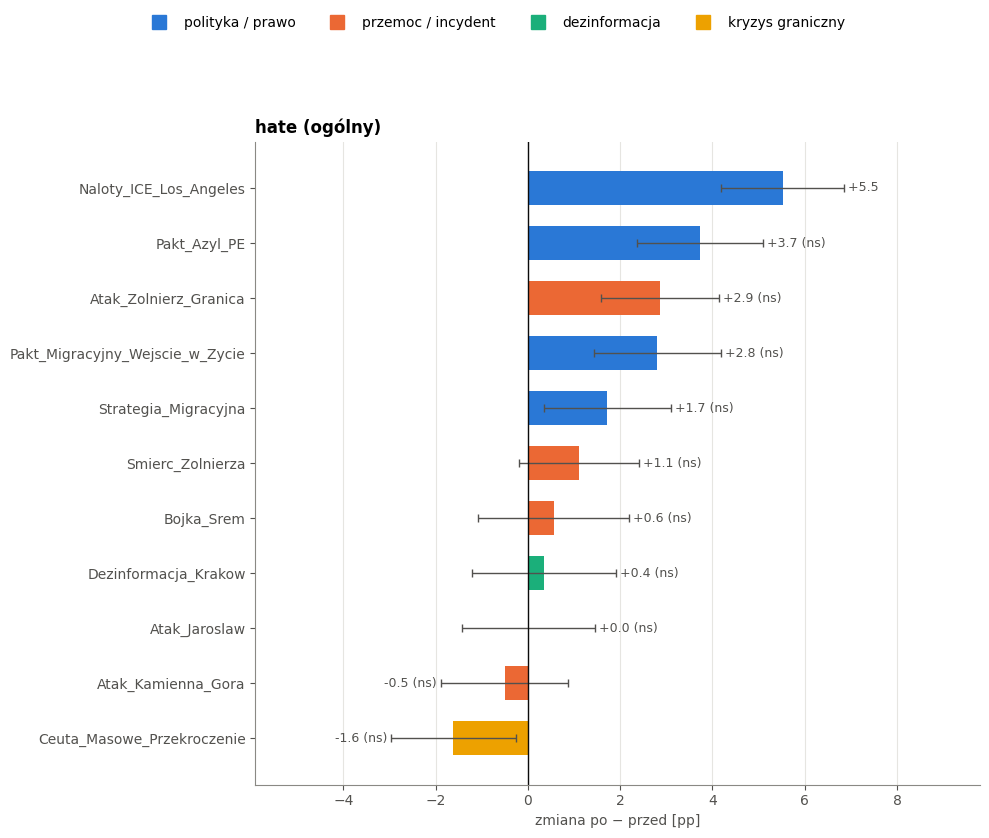

,największa,zmiana max [pp],najmniejsza,zmiana min [pp]
etykieta,,,,
hate,Naloty_ICE_Los_Angeles,5.52,Ceuta_Masowe_Przekroczenie,-1.61


In [5]:
order = eff[eff["etykieta"] == "hate"].sort_values("różnica pp")["event"].tolist()
fig, ax = plt.subplots(figsize=(10, 0.6 * len(order) + 1.8))
y = np.arange(len(order))
e = eff[eff["etykieta"] == "hate"].set_index("event").loc[order]
ax.barh(y, e["różnica pp"], height=0.62, color=[TYPE_COLORS[t] for t in e["typ"]])
ax.errorbar(e["różnica pp"], y, xerr=[e["różnica pp"] - e["CI lo pp"], e["CI hi pp"] - e["różnica pp"]],
            fmt="none", ecolor=INK2, capsize=3, lw=1)
for yi, (v, lo, hi, sig) in enumerate(zip(e["różnica pp"], e["CI lo pp"], e["CI hi pp"], e["istotne"])):
    right = v >= 0
    ax.text(hi if right else lo, yi, " {:+.1f}{} ".format(v, "" if sig else " (ns)"), va="center",
            ha="left" if right else "right", color=INK2, fontsize=9)
ax.axvline(0, color=INK, lw=1)
ax.margins(x=0.3)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("zmiana po − przed [pp]")
ax.set_title(LABEL_NAMES["hate"])
ax.set_yticks(y, order)
type_legend(fig)
plt.show()

rank = (eff.sort_values("różnica pp", ascending=False).groupby("etykieta", sort=False)
        .agg(największa=("event", "first"), **{"zmiana max [pp]": ("różnica pp", "first")},
             najmniejsza=("event", "last"), **{"zmiana min [pp]": ("różnica pp", "last")})
        .reindex(list(LABEL_SETS)))
display(rank.round(2))

## 3. Czy wydarzenia **ogólnie** podwyższają hejt? (test łączny)

Każde wydarzenie to jeden „eksperyment”. Trzy podejścia (jak u zespołu):

1. **Test znaków** – w ilu wydarzeniach z `k` odsetek wzrósł? Bez efektu wzrost i spadek byłyby równie prawdopodobne.
2. **Metaanaliza efektów losowych** – łączy OR z poszczególnych wydarzeń w **jeden wspólny OR** (DerSimonian–Laird +
   poprawka Hartung–Knapp). **I²** = jaka część różnic między wydarzeniami to prawdziwe różnice, a nie szum. **To główny wynik.**
3. **Jeden model na wszystkich komentarzach** – regresja `y ~ po + C(event)` z klastrami po wątku.

In [6]:
def meta_random(y, se):
    """Metaanaliza efektów losowych: DerSimonian–Laird + przedział Hartung–Knapp (t, k-1 df)."""
    y, se = np.asarray(y, float), np.asarray(se, float)
    k, w = len(y), 1 / se ** 2
    fixed = (w * y).sum() / w.sum()
    q = (w * (y - fixed) ** 2).sum()
    c = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (q - (k - 1)) / c) if k > 1 else 0.0
    ws = 1 / (se ** 2 + tau2)
    mu = (ws * y).sum() / ws.sum()
    if k == 1:
        return {"k": 1, "mu": mu, "lo": mu - 1.96 * se[0], "hi": mu + 1.96 * se[0], "p": 2 * stats.norm.sf(abs(mu / se[0])),
                "tau2": 0.0, "I2": np.nan, "p Q": np.nan}
    se_hk = max(np.sqrt((ws * (y - mu) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    t = stats.t.ppf(1 - ALPHA / 2, k - 1)
    return {"k": k, "mu": mu, "lo": mu - t * se_hk, "hi": mu + t * se_hk, "p": 2 * stats.t.sf(abs(mu / se_hk), k - 1),
            "tau2": tau2, "I2": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0, "p Q": stats.chi2.sf(q, k - 1)}


pooled_rows = []
for name, (col, cond) in LABEL_SETS.items():
    e = eff[eff["etykieta"] == name]
    m = meta_random(e["log OR"], e["se"])
    d = all_df[all_df[cond]] if cond else all_df
    fe = smf.logit("y ~ po + C(event)", data=d.assign(y=d[col].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
    n_up = int((e["różnica pp"] > 0).sum())
    pooled_rows.append({
        "etykieta": name, "wydarzeń": len(e), "wzrost w": f"{n_up}/{len(e)}",
        "istotny wzrost w": f"{int((e['istotne'] & (e['różnica pp'] > 0)).sum())}/{len(e)}",
        "p test znaków": stats.binomtest(n_up, len(e), 0.5, alternative="greater").pvalue,
        "średnia zmiana pp": e["różnica pp"].mean(),
        "OR łączny (meta)": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]), "p meta": m["p"],
        "I²": m["I2"], "p heterogeniczności": m["p Q"],
        "OR model wspólny": np.exp(fe.params["po"]), "p model wspólny": fe.pvalues["po"],
    })
pooled = pd.DataFrame(pooled_rows).set_index("etykieta")
pooled["p meta (Holm)"] = multipletests(pooled["p meta"], method="holm")[1]
pooled["wspólny wzrost istotny (meta)"] = (pooled["p meta (Holm)"] < ALPHA) & (pooled["OR łączny (meta)"] > 1)
display(fmt_p(pooled, 3))

,wydarzeń,wzrost w,istotny wzrost w,p test znaków,średnia zmiana pp,OR łączny (meta),OR lo,OR hi,p meta,I²,p heterogeniczności,OR model wspólny,p model wspólny,p meta (Holm),wspólny wzrost istotny (meta)
etykieta,,,,,,,,,,,,,,,
hate,11,9/11,1/11,0.0327,1.507,1.07,1.002,1.143,0.0448,0.666,0.00089,1.073,4.66e-05,0.0448,True


### Wykres lasu (forest plot)

Każdy wiersz to jedno wydarzenie: kropka = OR, kreska = 95% CI. Romb na dole = **wspólny OR z metaanalizy**.
Linia przerywana OR = 1 oznacza „brak zmiany”.

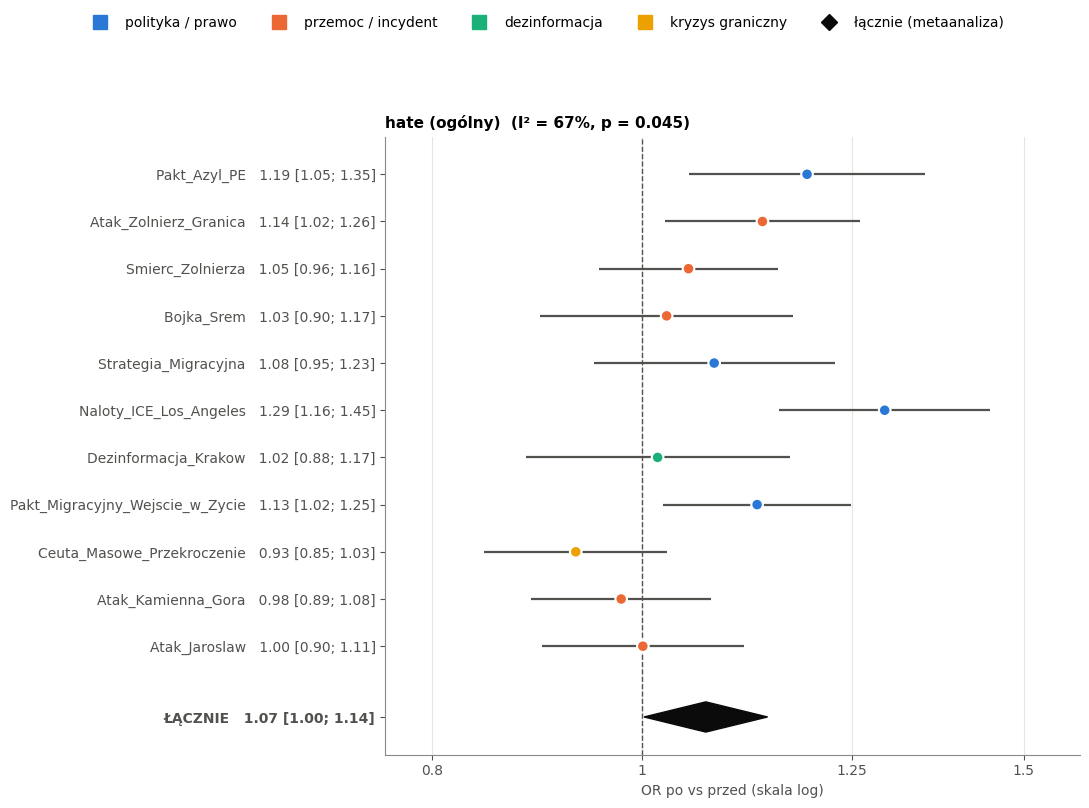

In [7]:
fig, ax = plt.subplots(figsize=(11, 0.5 * len(EVENT_ORDER) + 2.6))
name = "hate"
e = eff[eff["etykieta"] == name].set_index("event").loc[EVENT_ORDER]
r = pooled.loc[name]
y = np.arange(len(EVENT_ORDER))[::-1] + 1.5
ax.hlines(y, e["OR lo"], e["OR hi"], color=INK2, lw=1.6)
ax.scatter(e["OR"], y, s=70, color=[TYPE_COLORS[t] for t in e["typ"]], edgecolor="white", linewidth=1.5, zorder=3)
ax.fill([r["OR lo"], r["OR łączny (meta)"], r["OR hi"], r["OR łączny (meta)"]], [0, 0.32, 0, -0.32], color=INK, zorder=3)
ax.axvline(1, color=INK2, ls="--", lw=1)
ax.set_xscale("log")
xmin, xmax = min(e["OR lo"].min(), r["OR lo"]) * 0.9, max(e["OR hi"].max(), r["OR hi"]) * 1.1
ax.set_xlim(xmin, xmax)
ticks = [t for t in [0.25, 0.33, 0.5, 0.67, 0.8, 1, 1.25, 1.5, 2, 3, 4, 6] if xmin <= t <= xmax]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.xaxis.set_minor_locator(mticker.NullLocator())
labels = [f"{ev}   {o:.2f} [{lo:.2f}; {hi:.2f}]" for ev, o, lo, hi in zip(e.index, e["OR"], e["OR lo"], e["OR hi"])]
ax.set_yticks([*y, 0], [*labels, f"ŁĄCZNIE   {r['OR łączny (meta)']:.2f} [{r['OR lo']:.2f}; {r['OR hi']:.2f}]"])
ax.get_yticklabels()[-1].set_fontweight("bold")
ax.set_ylim(-0.8, y.max() + 0.8)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("OR po vs przed (skala log)")
i2 = "–" if np.isnan(r["I²"]) else f"{r['I²']:.0%}"
ax.set_title(f"{LABEL_NAMES[name]}  (I² = {i2}, p = {r['p meta']:.2g})", fontsize=11)
type_legend(fig, extra=[(plt.Line2D([], [], marker="D", ls="", ms=8, color=INK), "łącznie (metaanaliza)")])
plt.show()

### 3b. Analiza wrażliwości: okna bez nakładania

Te same obliczenia, ale każde wydarzenie ma **symetryczne okno ±`TRIM_WINDOW` dni**, tak żeby żaden komentarz nie
należał do dwóch wydarzeń. Jeśli wnioski są podobne jak wyżej – są odporne na nakładanie się okien.

In [8]:
trim_df = pd.concat([all_df[(all_df["event"] == e) & all_df["relative_day"].between(-w, w)]
                     for e, w in TRIM_WINDOW.items() if e in EVENT_ORDER])

rows = []
for event in EVENT_ORDER:
    d = trim_df[trim_df["event"] == event]
    for name, (col, cond) in LABEL_SETS.items():
        dd = d[d[cond]] if cond else d
        try:
            rows.append({"etykieta": name, "event": event, **event_effect(dd, col)})
        except Exception as e:
            print(f"{event}: pominięte w oknie bez nakładania ({type(e).__name__})")
eff_trim = pd.DataFrame(rows)

cmp_rows = []
for name in LABEL_SETS:
    a = eff[eff["etykieta"] == name].set_index("event")
    b = eff_trim[eff_trim["etykieta"] == name].set_index("event")
    for ev in EVENT_ORDER:
        if ev not in b.index:
            continue
        cmp_rows.append({"etykieta": name, "event": ev, "okno": f"±{TRIM_WINDOW[ev]}",
                         "zmiana pp (±28)": a.loc[ev, "różnica pp"], "zmiana pp (bez nakładania)": b.loc[ev, "różnica pp"],
                         "OR (±28)": a.loc[ev, "OR"], "OR (bez nakładania)": b.loc[ev, "OR"],
                         "p (bez nakładania)": b.loc[ev, "p"]})
    m = meta_random(b["log OR"], b["se"])
    cmp_rows.append({"etykieta": name, "event": "ŁĄCZNIE (meta)", "okno": "",
                     "zmiana pp (±28)": a["różnica pp"].mean(), "zmiana pp (bez nakładania)": b["różnica pp"].mean(),
                     "OR (±28)": pooled.loc[name, "OR łączny (meta)"], "OR (bez nakładania)": np.exp(m["mu"]),
                     "p (bez nakładania)": m["p"]})
    pooled.loc[name, "OR meta bez nakładania"] = np.exp(m["mu"])
    pooled.loc[name, "OR lo bez nakładania"] = np.exp(m["lo"])
    pooled.loc[name, "OR hi bez nakładania"] = np.exp(m["hi"])
    pooled.loc[name, "p meta bez nakładania"] = m["p"]
    pooled.loc[name, "wzrost w (bez nakładania)"] = f"{int((b['różnica pp'] > 0).sum())}/{len(b)}"
display(fmt_p(pd.DataFrame(cmp_rows).set_index(["etykieta", "event"]), 3))

okno  zmiana pp (±28)  \
etykieta event                                                   
hate     Pakt_Azyl_PE                     ±23            3.729   
         Atak_Zolnierz_Granica             ±4            2.866   
         Smierc_Zolnierza                  ±4            1.112   
         Bojka_Srem                       ±16            0.571   
         Strategia_Migracyjna             ±16            1.724   
         Naloty_ICE_Los_Angeles           ±28            5.524   
         Dezinformacja_Krakow             ±28            0.351   
         Pakt_Migracyjny_Wejscie_w_Zycie  ±23            2.809   
         Ceuta_Masowe_Przekroczenie        ±7           -1.614   
         Atak_Kamienna_Gora                ±7           -0.506   
         Atak_Jaroslaw                    ±15            0.014   
         ŁĄCZNIE (meta)                                  1.507   

                                          zmiana pp (bez nakładania)  \
etykieta event                                                         
hate     Pakt_Azyl_PE                                          4.877   
         Atak_Zolnierz_Granica                                 0.763   
         Smierc_Zolnierza                                      1.373   
         Bojka_Srem                                            0.783   
         Strategia_Migracyjna                                 -0.001   
         Naloty_ICE_Los_Angeles                                5.524   
         Dezinformacja_Krakow                                  0.351   
         Pakt_Migracyjny_Wejscie_w_Zycie                       1.984   
         Ceuta_Masowe_Przekroczenie                           -1.652   
         Atak_Kamienna_Gora                                   -3.298   
         Atak_Jaroslaw                                        -0.840   
         ŁĄCZNIE (meta)                                        0.897   

                                          OR (±28)  OR (bez nakładania)  \
etykieta event                                                            
hate     Pakt_Azyl_PE                        1.192                1.257   
         Atak_Zolnierz_Granica               1.136                1.035   
         Smierc_Zolnierza                    1.050                1.060   
         Bojka_Srem                          1.026                1.036   
         Strategia_Migracyjna                1.079                1.000   
         Naloty_ICE_Los_Angeles              1.294                1.294   
         Dezinformacja_Krakow                1.016                1.016   
         Pakt_Migracyjny_Wejscie_w_Zycie     1.130                1.090   
         Ceuta_Masowe_Przekroczenie          0.932                0.929   
         Atak_Kamienna_Gora                  0.978                0.865   
         Atak_Jaroslaw                       1.001                0.964   
         ŁĄCZNIE (meta)                      1.070                1.052   

                                         p (bez nakładania)  
etykieta event                                               
hate     Pakt_Azyl_PE                                0.0018  
         Atak_Zolnierz_Granica                        0.786  
         Smierc_Zolnierza                             0.544  
         Bojka_Srem                                   0.647  
         Strategia_Migracyjna                             1  
         Naloty_ICE_Los_Angeles                     6.9e-06  
         Dezinformacja_Krakow                         0.819  
         Pakt_Migracyjny_Wejscie_w_Zycie              0.109  
         Ceuta_Masowe_Przekroczenie                   0.409  
         Atak_Kamienna_Gora                           0.121  
         Atak_Jaroslaw                                0.586  
         ŁĄCZNIE (meta)                               0.215

## 4. Czy efekt zależy od typu wydarzenia?

- **Tabela**: średnia zmiana (pp) i łączny OR (metaanaliza) osobno dla każdego typu i zasięgu.
- **Test różnicy typów**: w modelu `y ~ C(event) + po + po:C(typ)` (klastry po wątku) człon `po:C(typ)` mówi,
  czy efekt „po” różni się między typami.

⚠️ **Uwaga (jak u zespołu):** w każdym typie jest tylko kilka wydarzeń, więc „typ” prawie pokrywa się z konkretnym
wydarzeniem. Traktuj tę część **opisowo**. Typy i zasięgi są przypisane ręcznie w `EVENT_META`.

In [9]:
def group_test(d, col, grp):
    if d[grp].nunique() < 2:
        return np.nan
    try:
        m = smf.logit(f"y ~ C(event) + po + po:C({grp})", data=d.assign(y=d[col].astype(int))).fit(
            disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]}, maxiter=200)
    except Exception as e:
        print(f"test {grp} pominięty: {type(e).__name__}")
        return np.nan
    idx = [i for i, n in enumerate(m.params.index) if n.startswith(f"po:C({grp})")]
    if not idx:
        return np.nan
    return float(m.wald_test(np.eye(len(m.params))[idx], scalar=True).pvalue)


type_rows, test_rows = [], []
for name, (col, cond) in LABEL_SETS.items():
    d = all_df[all_df[cond]] if cond else all_df
    test_rows.append({"etykieta": name, "p różnica typów": group_test(d, col, "typ"),
                      "p różnica zasięgu (PL vs zagranica)": group_test(d, col, "zasieg")})
    for grp in ["typ", "zasieg"]:
        for g, e in eff[eff["etykieta"] == name].groupby(grp, sort=False):
            m = meta_random(e["log OR"], e["se"])
            type_rows.append({"etykieta": name, "podział": grp, "grupa": g, "wydarzenia": ", ".join(e["event"]),
                              "średnia zmiana pp": e["różnica pp"].mean(), "OR łączny": np.exp(m["mu"]),
                              "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"])})

by_type = pd.DataFrame(type_rows)
display(by_type.set_index(["etykieta", "podział", "grupa"]).round(2))
display(fmt_p(pd.DataFrame(test_rows).set_index("etykieta"), 3))

wydarzenia  \
etykieta podział grupa                                                                                                                                                    
hate     typ     polityka / prawo                                           Pakt_Azyl_PE, Strategia_Migracyjna, Naloty_ICE_Los_Angeles, Pakt_Migracyjny_Wejscie_w_Zycie   
                 przemoc / incydent                                              Atak_Zolnierz_Granica, Smierc_Zolnierza, Bojka_Srem, Atak_Kamienna_Gora, Atak_Jaroslaw   
                 dezinformacja                                                                                                                     Dezinformacja_Krakow   
                 kryzys graniczny                                                                                                            Ceuta_Masowe_Przekroczenie   
         zasieg  UE / zagranica                                       Pakt_Azyl_PE, Naloty_ICE_Los_Angeles, Pakt_Migracyjny_Wejscie_w_Zycie, Ceuta_Masowe_Przekroczenie   
                 Polska              Atak_Zolnierz_Granica, Smierc_Zolnierza, Bojka_Srem, Strategia_Migracyjna, Dezinformacja_Krakow, Atak_Kamienna_Gora, Atak_Jaroslaw   

                                     średnia zmiana pp  OR łączny  OR lo  \
etykieta podział grupa                                                     
hate     typ     polityka / prawo                 3.45       1.17   1.04   
                 przemoc / incydent               0.81       1.04   0.96   
                 dezinformacja                    0.35       1.02   0.88   
                 kryzys graniczny                -1.61       0.93   0.85   
         zasieg  UE / zagranica                   2.61       1.13   0.89   
                 Polska                           0.88       1.04   0.99   

                                     OR hi  
etykieta podział grupa                      
hate     typ     polityka / prawo     1.33  
                 przemoc / incydent   1.12  
                 dezinformacja        1.17  
                 kryzys graniczny     1.03  
         zasieg  UE / zagranica       1.42  
                 Polska               1.10

,p różnica typów,p różnica zasięgu (PL vs zagranica)
etykieta,,
hate,0.000381,0.0441


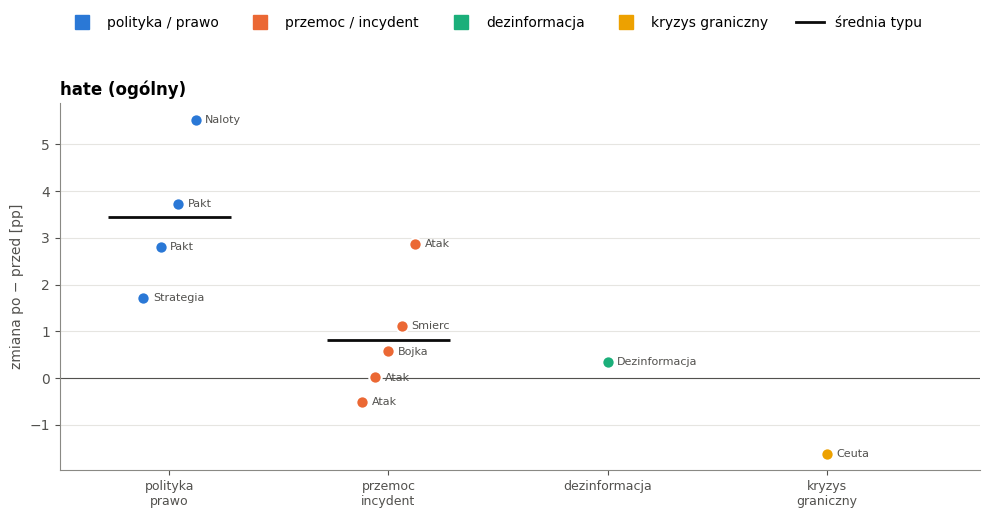

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.2))
e = eff[eff["etykieta"] == "hate"]
for xi, t in enumerate(TYPE_ORDER):
    g = e[e["typ"] == t].sort_values("różnica pp")
    if g.empty:
        continue
    xs = xi + np.linspace(-0.12, 0.12, len(g)) if len(g) > 1 else np.array([xi])
    ax.scatter(xs, g["różnica pp"], s=80, color=TYPE_COLORS[t], edgecolor="white", linewidth=1.5, zorder=3)
    if len(g) > 1:
        ax.hlines(g["różnica pp"].mean(), xi - 0.28, xi + 0.28, color=INK, lw=2)
    for x_, v, ev in zip(xs, g["różnica pp"], g["event"]):
        ax.annotate(ev.split("_")[0], (x_, v), xytext=(7, 0), textcoords="offset points", va="center",
                    fontsize=8, color=INK2)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(range(len(TYPE_ORDER)), [t.replace(" / ", "\n").replace(" ", "\n") for t in TYPE_ORDER], fontsize=9)
ax.set_xlim(-0.5, len(TYPE_ORDER) - 0.3)
ax.set_ylabel("zmiana po − przed [pp]")
ax.set_title(LABEL_NAMES["hate"])
type_legend(fig, extra=[(plt.Line2D([], [], color=INK, lw=2), "średnia typu")])
plt.show()

## 5. Przebieg w czasie – wszystkie wydarzenia na wspólnej osi

Dla każdego wydarzenia: dzienny odsetek `hate` **minus jego własna średnia sprzed wydarzenia** (w pp),
wygładzony średnią kroczącą `ROLL_DAYS` dni. Gruba czarna linia = średnia wszystkich wydarzeń. Wartość > 0 = więcej niż zwykle.

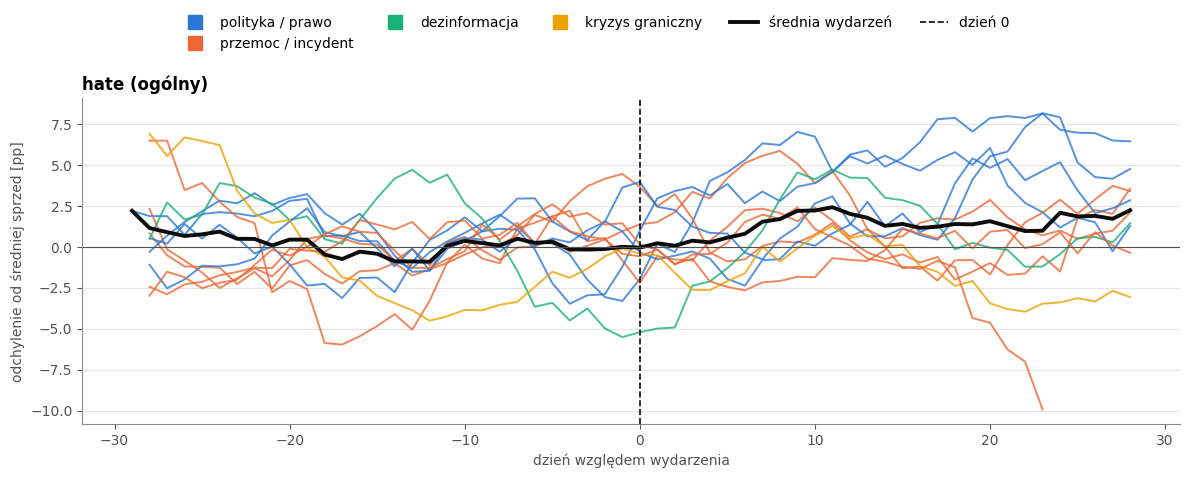

In [11]:
fig, ax = plt.subplots(figsize=(12, 4.8))
lab = "hate"
curves = {}
for ev in EVENT_ORDER:
    d = all_df[all_df["event"] == ev]
    g = d.groupby("relative_day")[lab].agg(["mean", "size"])
    g = g[g["size"] >= MIN_DAILY_N].reindex(range(d["relative_day"].min(), d["relative_day"].max() + 1))
    base = d.loc[d["okres"] == "przed", lab].mean()
    s = (100 * (g["mean"] - base)).rolling(ROLL_DAYS, center=True, min_periods=3).mean()
    curves[ev] = s
    ax.plot(s.index, s.values, color=TYPE_COLORS[EVENT_META.get(ev, ("inne", "?"))[0]], lw=1.4, alpha=0.8)
avg = pd.DataFrame(curves).mean(axis=1)
ax.plot(avg.index, avg.values, color=INK, lw=2.8)
ax.axvline(0, color=INK, ls="--", lw=1.2)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xlabel("dzień względem wydarzenia")
ax.set_ylabel("odchylenie od średniej sprzed [pp]")
ax.set_title(LABEL_NAMES[lab])
type_legend(fig, extra=[(plt.Line2D([], [], color=INK, lw=2.8), "średnia wydarzeń"),
                        (plt.Line2D([], [], color=INK, ls="--", lw=1.2), "dzień 0")])
plt.show()

## 6. Aktywność: czy po wydarzeniu pisze się więcej?

Liczba komentarzy na dzień przed i po oraz krotność wzrostu. Korelacja Spearmana sprawdza, czy wydarzenia,
które bardziej „rozkręciły” dyskusję, mają też większy wzrost hejtu (przy kilku wydarzeniach – tylko orientacyjnie).

In [12]:
act = (all_df.groupby(["event", "okres"])
       .agg(n=("comment_id", "size"), dni=("relative_day", "nunique"))
       .assign(na_dzien=lambda x: x["n"] / x["dni"])["na_dzien"].unstack("okres")
       .reindex(EVENT_ORDER)[["przed", "po"]])
act.columns = ["komentarzy/dzień przed", "komentarzy/dzień po"]
act["wzrost ×"] = act["komentarzy/dzień po"] / act["komentarzy/dzień przed"]
for name in LABELS:
    act[f"zmiana {name} [pp]"] = eff[eff["etykieta"] == name].set_index("event")["różnica pp"]
display(act.round(2))
for name in LABELS:
    if len(act) > 2:
        rho, p = stats.spearmanr(act["wzrost ×"], act[f"zmiana {name} [pp]"])
        print(f"Spearman: wzrost aktywności vs zmiana {name}: rho = {rho:.2f}, p = {p:.3g} (n = {len(act)})")

,komentarzy/dzień przed,komentarzy/dzień po,wzrost ×,zmiana hate [pp]
event,,,,
Pakt_Azyl_PE,256.00,361.83,1.41,3.73
Atak_Zolnierz_Granica,332.46,401.28,1.21,2.87
Smierc_Zolnierza,350.32,370.10,1.06,1.11
Bojka_Srem,162.79,353.14,2.17,0.57
Strategia_Migracyjna,338.82,311.31,0.92,1.72
Naloty_ICE_Los_Angeles,323.43,325.34,1.01,5.52
Dezinformacja_Krakow,224.46,251.24,1.12,0.35
Pakt_Migracyjny_Wejscie_w_Zycie,337.86,323.55,0.96,2.81
Ceuta_Masowe_Przekroczenie,357.71,320.55,0.90,-1.61


Spearman: wzrost aktywności vs zmiana hate: rho = 0.37, p = 0.259 (n = 11)


## 7. Słowa w hejcie

Tokenizacja jak u zespołu (małe litery, bez linków, ≥ 3 litery, bez stop-słów, bez lematyzacji).

- **7.1** najczęstsze słowa w `hate` – łącznie i w każdym wydarzeniu,
- **7.2** słowa **charakterystyczne** dla wydarzenia – częstsze w hejcie tego wydarzenia niż w hejcie pozostałych
  (ważony log-odds ratio z priorem Dirichleta, Monroe i in. 2008; `z` > 2 ≈ wyraźnie częstsze),
- **7.3** słowa, które **najbardziej rosną po wydarzeniu** (wszystkie wydarzenia razem, po vs przed).

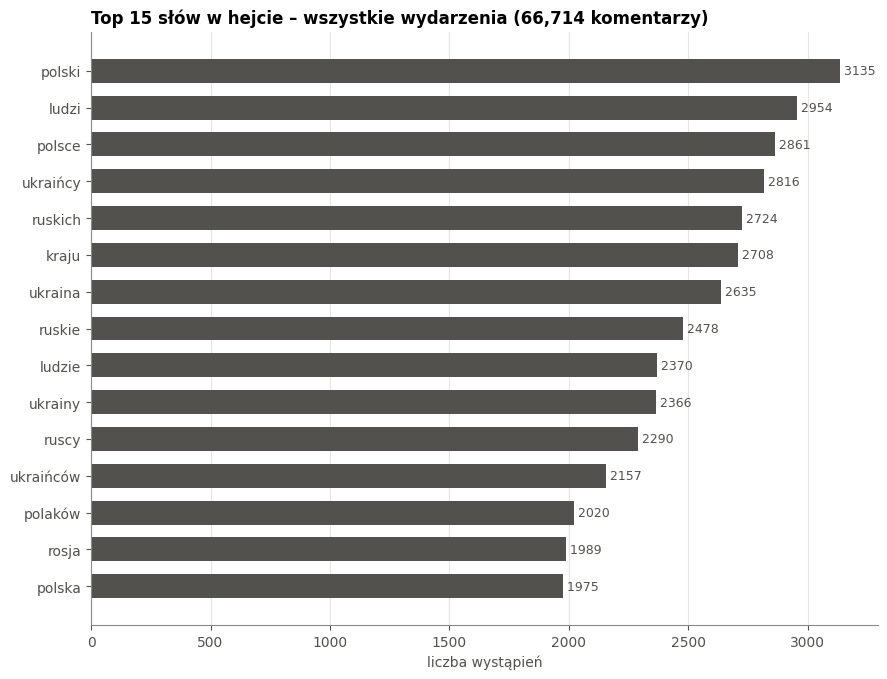

Najczęstsze słowa w hate w każdym wydarzeniu:


,Pakt_Azyl_PE,Atak_Zolnierz_Granica,Smierc_Zolnierza,Bojka_Srem,Strategia_Migracyjna,Naloty_ICE_Los_Angeles,Dezinformacja_Krakow,Pakt_Migracyjny_Wejscie_w_Zycie,Ceuta_Masowe_Przekroczenie,Atak_Kamienna_Gora,Atak_Jaroslaw
1,ukraińcy (293),ludzi (378),ludzi (376),ukraina (225),polski (321),pis (535),ukraina (242),polski (396),polsce (320),ludzi (301),ruskich (251)
2,ruskich (293),kraju (358),granicy (358),ruskich (217),kraju (312),polski (339),ukraińcy (233),ukraińcy (380),ukraińców (314),polsce (282),ruskie (239)
3,ruscy (273),granicy (340),kraju (338),ludzi (213),ludzi (297),polsce (258),ruskich (230),ukraina (361),polski (313),ukraińców (276),ukraina (238)
4,ukraina (270),polski (333),polski (322),polski (212),polsce (295),ludzi (251),rosja (199),ukrainy (310),ukraińcy (305),ukraińcy (262),ukraińcy (225)
5,polsce (267),polsce (284),polsce (270),ruscy (206),ludzie (257),kraju (246),polsce (198),polsce (303),ludzi (296),polski (251),ukrainy (222)
6,rosja (266),ruskich (278),ruskie (264),ruskie (206),ukraina (233),ludzie (235),ruskie (195),ludzi (289),ukraina (287),ruskich (248),ruscy (218)
7,kraju (263),ruskie (273),ruskich (264),ukraińcy (205),ukraińcy (230),imigrantów (230),ruscy (195),ukraińców (287),polaków (264),ukraina (243),polski (215)
8,polski (252),ludzie (264),ludzie (257),kraju (200),ruskich (219),ukraińcy (209),ukrainy (189),ruskich (287),ruskich (264),ludzie (241),ukraińców (204)
9,ruskie (251),ruscy (263),ruscy (247),polsce (196),ukrainy (213),tusk (181),polski (181),ruskie (274),ludzie (247),polaków (234),ludzi (204)
10,ukrainy (246),kraj (257),kraj (236),ukrainy (183),polska (191),polska (179),rosji (181),polska (266),ruskie (236),kraju (224),wojny (203)


In [13]:
STOPWORDS_PL = set('''
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
'''.split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")


def tokenize(text):
    return [t for t in TOKEN_RE.findall(URL_RE.sub(" ", text.lower())) if t not in STOPWORDS_PL]


def count_words(texts):
    return Counter(t for txt in texts for t in tokenize(txt))


hm = all_df[all_df["hate"]]
counts = {ev: count_words(hm.loc[hm["event"] == ev, "text"]) for ev in EVENT_ORDER}
total = sum(counts.values(), Counter())

top = pd.DataFrame(total.most_common(TOP_N_WORDS), columns=["słowo", "liczba"])
fig, ax = plt.subplots(figsize=(9, 0.38 * TOP_N_WORDS + 1.2))
ax.barh(top["słowo"][::-1], top["liczba"][::-1], color=INK2, height=0.65)
for yi, v in enumerate(top["liczba"][::-1]):
    ax.text(v, yi, f" {v}", va="center", color=INK2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("liczba wystąpień")
ax.set_title(f"Top {TOP_N_WORDS} słów w hejcie – wszystkie wydarzenia ({len(hm):,} komentarzy)")
plt.tight_layout()
plt.show()

print("Najczęstsze słowa w hate w każdym wydarzeniu:")
display(pd.DataFrame({ev: [f"{w} ({n})" for w, n in counts[ev].most_common(TOP_N_WORDS)] +
                          [""] * (TOP_N_WORDS - len(counts[ev].most_common(TOP_N_WORDS))) for ev in EVENT_ORDER},
                     index=range(1, TOP_N_WORDS + 1)))

In [14]:
def log_odds(c1, c2, prior, min_count=5):
    """Ważony log-odds ratio z informatywnym priorem Dirichleta (Monroe i in. 2008); z > 0 = częstsze w c1."""
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["słowo", "n", "n porównanie", "z"]).sort_values("z", ascending=False)


distinct = {}
for ev in EVENT_ORDER:
    rest = total - counts[ev]
    lo_ = log_odds(counts[ev], rest, total).head(TOP_N_WORDS)
    distinct[ev] = [f"{w} (z={z:.1f})" for w, z in zip(lo_["słowo"], lo_["z"])]
print("7.2 Słowa charakterystyczne dla hejtu w danym wydarzeniu (vs hejt w pozostałych wydarzeniach):")
display(pd.DataFrame({ev: v + [""] * (TOP_N_WORDS - len(v)) for ev, v in distinct.items()}, index=range(1, TOP_N_WORDS + 1)))

7.2 Słowa charakterystyczne dla hejtu w danym wydarzeniu (vs hejt w pozostałych wydarzeniach):


,Pakt_Azyl_PE,Atak_Zolnierz_Granica,Smierc_Zolnierza,Bojka_Srem,Strategia_Migracyjna,Naloty_ICE_Los_Angeles,Dezinformacja_Krakow,Pakt_Migracyjny_Wejscie_w_Zycie,Ceuta_Masowe_Przekroczenie,Atak_Kamienna_Gora,Atak_Jaroslaw
1,oligarchów (z=3.7),granicy (z=5.9),granicy (z=6.6),patrol (z=3.0),afryki (z=3.1),pis (z=10.1),tomahawki (z=3.6),upa (z=7.5),autobusie (z=2.8),narodowościowym (z=2.4),afd (z=3.5)
2,ooooo (z=2.7),strzelać (z=4.0),strzelać (z=4.5),kurska (z=3.0),nieokupowane (z=2.9),imigrantów (z=4.7),węgrzy (z=3.4),order (z=3.8),mzk (z=2.6),hiszpania (z=2.3),alerty (z=3.1)
3,mbank (z=2.5),żołnierz (z=3.6),płot (z=4.3),patrole (z=2.7),azylu (z=2.6),trzaskowski (z=4.3),ciastko (z=3.0),rybę (z=3.5),braun (z=2.6),wildberries (z=2.2),radek (z=2.9)
4,rosja (z=2.5),żołnierza (z=3.6),granicę (z=3.9),kurskim (z=2.3),amfa (z=2.5),wizy (z=4.0),węgier (z=2.9),batyr (z=3.1),ukraińców (z=2.5),hiszpanii (z=2.2),nato (z=2.6)
5,amunicję (z=2.3),płot (z=3.4),żołnierz (z=3.6),milicja (z=2.3),utrzymanie (z=2.4),migrantów (z=3.8),węgry (z=2.9),stanowskiego (z=3.1),brauna (z=2.4),magazyny (z=2.2),sikorski (z=2.3)
6,rozkradną (z=2.3),granicę (z=3.4),żołnierza (z=3.3),kursk (z=2.2),skrzata (z=2.3),tusk (z=3.8),futra (z=2.8),zełeński (z=3.0),hiszpania (z=2.2),urządzają (z=2.2),północą (z=2.3)
7,trzeciego (z=2.2),żołnierze (z=3.0),szatan (z=3.1),kurski (z=2.2),wyłudzają (z=2.3),tuska (z=3.6),fermy (z=2.6),zelenski (z=2.8),ceuta (z=2.1),ceuta (z=2.2),kontrolerzy (z=2.3)
8,fab (z=2.1),żołnierzy (z=2.9),żołnierze (z=3.1),tereny (z=2.2),ubogacenie (z=2.2),wizach (z=3.5),trump (z=2.4),orderu (z=2.7),hiszpanii (z=2.1),autobusie (z=2.1),korei (z=2.3)
9,kaukazie (z=2.1),szatan (z=2.8),żołnierzy (z=3.1),kursku (z=2.2),europy (z=2.2),wiz (z=3.5),drony (z=2.4),dronowej (z=2.7),autobusu (z=2.1),brauna (z=2.1),tagu (z=2.3)
10,wykrwawienie (z=2.1),kurdej (z=2.6),nielegalnie (z=2.9),wyjeżdżając (z=2.1),patrol (z=2.1),pisu (z=3.5),waszą (z=2.3),wołyń (z=2.7),prawackie (z=2.1),sądach (z=2.1),alert (z=2.2)


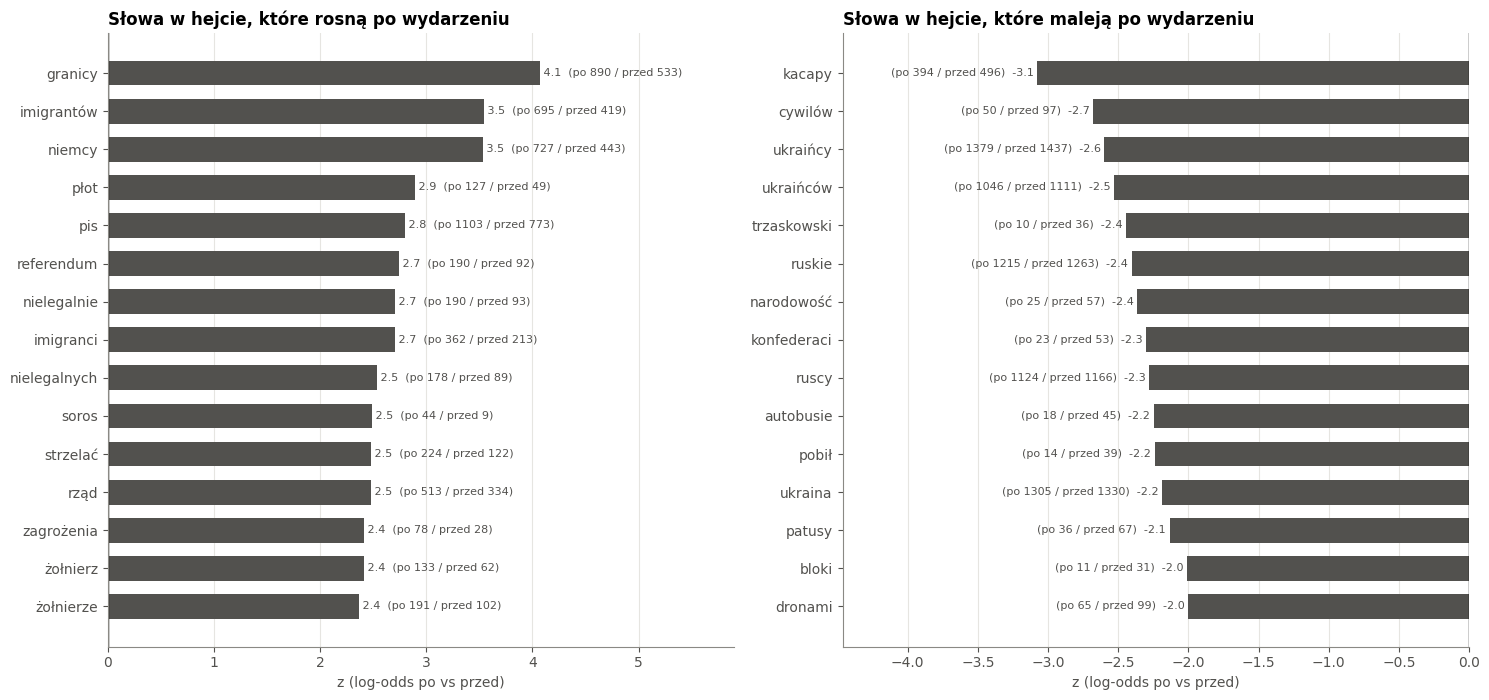

In [15]:
c_pre = count_words(hm.loc[hm["okres"] == "przed", "text"])
c_post = count_words(hm.loc[hm["okres"] == "po", "text"])
growth = log_odds(c_post, c_pre, c_pre + c_post, min_count=10)
grow = growth.head(TOP_N_WORDS)
fall = growth.sort_values("z").head(TOP_N_WORDS)

fig, axes = plt.subplots(1, 2, figsize=(15, 0.38 * TOP_N_WORDS + 1.4))
for ax, t, title in [(axes[0], grow, "rosną po wydarzeniu"), (axes[1], fall, "maleją po wydarzeniu")]:
    ax.barh(t["słowo"][::-1], t["z"][::-1], color=INK2, height=0.65)
    for yi, (z, n1, n0) in enumerate(zip(t["z"][::-1], t["n"][::-1], t["n porównanie"][::-1])):
        ax.text(z, yi, f" {z:.1f}  (po {n1} / przed {n0})" if z > 0 else f"(po {n1} / przed {n0})  {z:.1f} ",
                va="center", ha="left" if z > 0 else "right", color=INK2, fontsize=8)
    ax.axvline(0, color=INK, lw=1)
    ax.margins(x=0.45)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("z (log-odds po vs przed)")
    ax.set_title(f"Słowa w hejcie, które {title}")
plt.tight_layout()
plt.show()

## 8. Kogo obrażano? Grupy w hejcie po wydarzeniu

Odsetek komentarzy `hate` z okresu **po** wydarzeniu, które wymieniają daną grupę migrantów (słowa kluczowe zespołu;
komentarz może trafić do kilku grup). Liczone wśród **całego** hejtu, więc odsetki są niższe niż u zespołu (tam: hejt wobec migrantów).

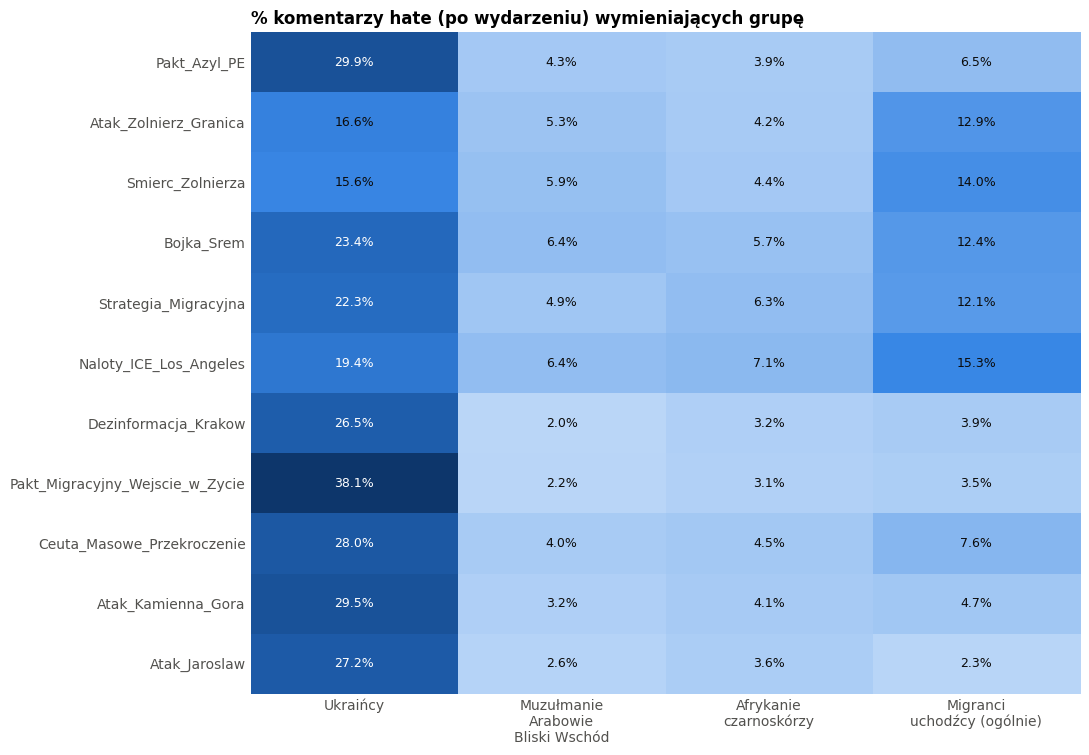

Zmiana po − przed [pp]:


,Ukraińcy,Muzułmanie / Arabowie / Bliski Wschód,Afrykanie / czarnoskórzy,Migranci / uchodźcy (ogólnie)
event,,,,
Pakt_Azyl_PE,-5.2,0.5,0.7,2.5
Atak_Zolnierz_Granica,-9.6,0.9,-0.5,6.0
Smierc_Zolnierza,-6.5,1.4,0.4,5.9
Bojka_Srem,-9.6,3.0,1.7,7.9
Strategia_Migracyjna,-1.6,-1.9,-0.4,0.4
Naloty_ICE_Los_Angeles,-1.1,2.3,2.7,3.9
Dezinformacja_Krakow,-8.6,-1.0,-0.7,-1.7
Pakt_Migracyjny_Wejscie_w_Zycie,5.7,-0.9,-3.2,-2.2
Ceuta_Masowe_Przekroczenie,-6.9,1.6,1.3,4.3


In [16]:
TARGET_GROUPS = {
    "Ukraińcy": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|slava|sława|chachoł|chochoł",
    "Muzułmanie / Arabowie / Bliski Wschód": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|kebab|szariat|meczet",
    "Afrykanie / czarnoskórzy": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "Migranci / uchodźcy (ogólnie)": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}
low = hm["text"].str.lower()
grp = pd.DataFrame({g: low.str.contains(rx, regex=True) for g, rx in TARGET_GROUPS.items()})
grp_pct = {okres: 100 * grp[hm["okres"] == okres].groupby(hm["event"]).mean().reindex(EVENT_ORDER)
           for okres in ["przed", "po"]}

tab = grp_pct["po"]
fig, ax = plt.subplots(figsize=(11, 0.55 * len(EVENT_ORDER) + 1.6))
ax.imshow(tab.values, cmap=BLUES, aspect="auto", vmin=0)
for (i, j), v in np.ndenumerate(tab.values):
    ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9,
            color="white" if v > 0.45 * np.nanmax(tab.values) else INK)
ax.set_xticks(range(tab.shape[1]), [c.replace(" / ", "\n") for c in tab.columns])
ax.set_yticks(range(len(tab)), tab.index)
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("% komentarzy hate (po wydarzeniu) wymieniających grupę")
plt.tight_layout()
plt.show()

print("Zmiana po − przed [pp]:")
display((grp_pct["po"] - grp_pct["przed"]).round(1))

## 9. Podsumowanie (generowane automatycznie)

In [17]:
print(f"{PLATFORM} | model: {MODEL_NAME} ({MODEL_DIR}), etykieta: {LABEL}\n")
for name, r in pooled.iterrows():
    e = eff[eff["etykieta"] == name].set_index("event")["różnica pp"]
    verdict = "ISTOTNY wspólny wzrost" if r["wspólny wzrost istotny (meta)"] else "brak istotnego wspólnego efektu"
    i2 = "–" if np.isnan(r["I²"]) else f"{r['I²']:.0%}"
    print(f"{LABEL_NAMES[name]}:\n"
          f"  wzrost w {r['wzrost w']} wydarzeń (istotny w {r['istotny wzrost w']}), średnio {r['średnia zmiana pp']:+.2f} pp\n"
          f"  metaanaliza: OR = {r['OR łączny (meta)']:.2f} [{r['OR lo']:.2f}; {r['OR hi']:.2f}], "
          f"p (Holm) = {r['p meta (Holm)']:.3g} -> {verdict}\n"
          f"  różnice między wydarzeniami: I² = {i2}\n"
          f"  okna bez nakładania: wzrost w {r['wzrost w (bez nakładania)']}, OR = {r['OR meta bez nakładania']:.2f} "
          f"[{r['OR lo bez nakładania']:.2f}; {r['OR hi bez nakładania']:.2f}], p = {r['p meta bez nakładania']:.3g}\n"
          f"  największa zmiana: {e.idxmax()} ({e.max():+.1f} pp), najmniejsza: {e.idxmin()} ({e.min():+.1f} pp)\n")
if skipped:
    print("Pominięte wydarzenia:", ", ".join(f"{k} ({v})" for k, v in skipped.items()))

# tabela do porównań między platformami / z wynikami zespołu
out = ROOT / "reports" / "hate_analysis_models"
out.mkdir(parents=True, exist_ok=True)
eff.assign(platform=PLATFORM, model=MODEL_DIR).to_csv(out / f"{PLATFORM}_event_effects.csv", index=False, encoding="utf-8-sig")
pooled.assign(platform=PLATFORM, model=MODEL_DIR).to_csv(out / f"{PLATFORM}_pooled.csv", encoding="utf-8-sig")
print("zapisano:", (out / f"{PLATFORM}_event_effects.csv").relative_to(ROOT), "i", (out / f"{PLATFORM}_pooled.csv").relative_to(ROOT))

wykop | model: HerBERT-HS (herbert), etykieta: hate_final

hate (ogólny):
  wzrost w 9/11 wydarzeń (istotny w 1/11), średnio +1.51 pp
  metaanaliza: OR = 1.07 [1.00; 1.14], p (Holm) = 0.0448 -> ISTOTNY wspólny wzrost
  różnice między wydarzeniami: I² = 67%
  okna bez nakładania: wzrost w 7/11, OR = 1.05 [0.97; 1.15], p = 0.215
  największa zmiana: Naloty_ICE_Los_Angeles (+5.5 pp), najmniejsza: Ceuta_Masowe_Przekroczenie (-1.6 pp)

zapisano: reports/hate_analysis_models/wykop_event_effects.csv i reports/hate_analysis_models/wykop_pooled.csv
